## Setup
Environment, imports, configuration print.

In [1]:
import sys, subprocess
import os

In [2]:
import sys, os
print(sys.executable)      # the python being used right now
print(sys.prefix)          # the environment folder
print(sys.version)
print(os.environ.get("VIRTUAL_ENV"), os.environ.get("CONDA_DEFAULT_ENV"))

/home/aa8624/thesis_2500/venv/bin/python
/home/aa8624/thesis_2500/venv
3.12.3 (main, Mar 23 2026, 19:04:32) [GCC 13.3.0]
None None


In [3]:
# List the key package versions in this environment 
print("python:", sys.executable)
print(subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
      .split("\n")[0:0] or "")
out = subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
print("\n".join(l for l in out.splitlines() if l.lower().split()[0:1] and l.lower().split()[0] in
      ("torch", "torchvision", "torchaudio", "transformers", "huggingface-hub", "open_clip_torch", "open-clip-torch")))

python: /home/aa8624/thesis_2500/venv/bin/python

open_clip_torch           3.3.0
torch                     2.11.0+cu128
torchvision               0.26.0+cu128
transformers              5.13.0


In [4]:
#Pick the GPU (index from nvidia-smi)
# a quiet GPU index from nvidia-smi
os.environ["CUDA_VISIBLE_DEVICES"] = "3"   

In [5]:
# Imports and config printout. 
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))         
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import size_config as sc
import config
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.preprocessing import StandardScaler

%matplotlib inline
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)


print("PROJECT_ROOT :", config.PROJECT_ROOT)
print("QUICK_RUN    :", config.QUICK_RUN, "  (True = tiny settings, NOT for final results)")
print("family set   :", config.ACTIVE_FAMILY_SET, "| models:", config.MODELS_TO_RUN)
print("seeds        :", config.EXPERIMENT_SEEDS)
try:
    import torch; print("torch        :", torch.__version__, "| CUDA:", torch.cuda.is_available())
except ImportError:
    print("torch not installed (only the logistic-regression models will work)")

PROJECT_ROOT : /data/aa8624/thesis_2500
QUICK_RUN    : False   (True = tiny settings, NOT for final results)
family set   : diffusion_split | models: ['spectral_lr', 'handcrafted_lr', 'lbp_lr', 'cnn_densenet', 'supcon', 'npr', 'clip_frozen', 'biomedclip_frozen', 'rad_dino', 'dinov2_frozen']
seeds        : [42, 43, 44]
torch        : 2.11.0+cu128 | CUDA: True


In [6]:
# Number of data-loader workers for the CNN detectors
config.CNN_NUM_WORKERS = 4

**Optional installs (commented out on purpose).** These two lines change the Python environment, so they are not run
automatically. Uncomment and run them once if `import open_clip` or the Hugging Face hub version fails in Stage 5, then restart the kernel.

In [9]:
# One-off environment fixes. Execute only once.
!{sys.executable} -m pip uninstall -y huggingface-hub
!{sys.executable} -m pip install "huggingface-hub>=1.5,<2.0"
%pip install open_clip_torch

Found existing installation: huggingface_hub 1.33.0
Uninstalling huggingface_hub-1.33.0:
  Successfully uninstalled huggingface_hub-1.33.0
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
Using cached huggingface_hub-1.33.0-py3-none-any.whl (846 kB)


Note: you may need to restart the kernel to use updated packages.


## Synthetic data generation

In [14]:
# Generate the three classical edit families (blob, copy-move, texture)
# =============================================================================
# -----------------------------------------------------------------------------
# VERIFY THAT CONFIG.PY SETTINGS
# -----------------------------------------------------------------------------
import importlib
import config
importlib.reload(config)          

print("Run folder               :", config.PROJECT_ROOT)
print("Images per pool          :", config.POOL_SIZE_PER_POOL)
print("Resize filter            :", config.GEN_RESIZE_FILTER)
print("Output format            :", config.GEN_IMAGE_FORMAT)
print("CycleGAN experiment      :", config.CYCLEGAN_EXPERIMENT_NAME)
print("CycleGAN epochs          :", config.CYCLEGAN_EPOCHS)
print("CycleGAN final checkpoint:", config.CYCLEGAN_FINAL_CHECKPOINT)
print("CycleGAN device          :", config.CYCLEGAN_DEVICE)

Run folder               : /data/aa8624/thesis_2500
Images per pool          : 2500
Resize filter            : lanczos
Output format            : PNG
CycleGAN experiment      : cyclegan_lanczos_256_150ep
CycleGAN epochs          : 150
CycleGAN final checkpoint: /data/aa8624/thesis_2500/data/calibration_cyclegan/checkpoints/cyclegan_lanczos_256_150ep/epoch_150.pth
CycleGAN device          : cuda


### Stage 1 (A) — Classical Image Processing Techniques

In [15]:
# -----------------------------------------------------------------------------
# IP Generation
# -----------------------------------------------------------------------------

%run stage1_generation/ip_blob_generate.py

%run stage1_generation/ip_copy_generate.py

%run stage1_generation/ip_texture_generate.py

FINAL BLOB SYNTHETIC DATASET GENERATION

Total source images: 2500

Split counts:
  train       : 1500 (expected 1500)
  val         : 500 (expected 500)
  test        : 500 (expected 500)

Fixed safe ROI:
  x      = 38
  y      = 32
  width  = 179
  height = 192

----------------------------------------------------------------------
Generating train: 1500 images
----------------------------------------------------------------------
Completed train

----------------------------------------------------------------------
Generating val: 500 images
----------------------------------------------------------------------
Completed val

----------------------------------------------------------------------
Generating test: 500 images
----------------------------------------------------------------------
Completed test

GENERATION SUMMARY

Successfully generated: 2500
Missing source images: 0
Generation errors: 0

Synthetic images by split:
split
test      500
train    1500
val       500

Synt

Progress: 2350/2500 | successful=2350 | errors=0
Progress: 2375/2500 | successful=2375 | errors=0
Progress: 2400/2500 | successful=2400 | errors=0
Progress: 2425/2500 | successful=2425 | errors=0
Progress: 2450/2500 | successful=2450 | errors=0
Progress: 2475/2500 | successful=2475 | errors=0
Progress: 2500/2500 | successful=2500 | errors=0

FINAL COPY-MOVE PRODUCTION — VERIFICATION
Expected images: 2500
Successful: 2500
Errors: 0

Generated images by split:
split
test      500
train    1500
val       500
Name: count, dtype: int64

Generated images by disease status:
disease_status
pathology    1250
normal       1250
Name: count, dtype: int64

Sampled patch fraction range:
min = 0.2501
max = 0.3499

Sampled rotation range:
min = 0.0001
max = 14.9977

Sampled scale range:
min = 1.0000
max = 1.1500

Source/destination separation:
minimum observed = 54.57
minimum required = 54.00

All separation constraints passed:
True

Files on disk:
train        images=1500 masks=1500
val          imag


Metadata: /data/aa8624/thesis_2500/data/synthetic/IP/blob/metadata/blob_synthetic_metadata.csv
Rows: 2500

Blob
Metadata rows: 2500
Selected examples: 3

Example 1:
  Split:     test
  Disease:   normal
  Real:      /data/aa8624/thesis_2500/data/real/test/normal/p11720780_s56271117_9293f649-267589ed-21194541-6f9ab291-64448feb.jpg
  Synthetic: /data/aa8624/thesis_2500/data/synthetic/IP/blob/test/p11720780_s56271117_9293f649-267589ed-21194541-6f9ab291-64448feb.png
  Mask:      /data/aa8624/thesis_2500/data/synthetic/IP/blob/masks/test/p11720780_s56271117_9293f649-267589ed-21194541-6f9ab291-64448feb_mask.png
  Changed pixels: 3592

Example 2:
  Split:     test
  Disease:   pathology
  Real:      /data/aa8624/thesis_2500/data/real/test/pathology/p15711610_s51269423_d7f7d3a3-93858d0d-d6ffedf0-f9b27cb1-483b6edb.jpg
  Synthetic: /data/aa8624/thesis_2500/data/synthetic/IP/blob/test/p15711610_s51269423_d7f7d3a3-93858d0d-d6ffedf0-f9b27cb1-483b6edb.png
  Mask:      /data/aa8624/thesis_2500/data/

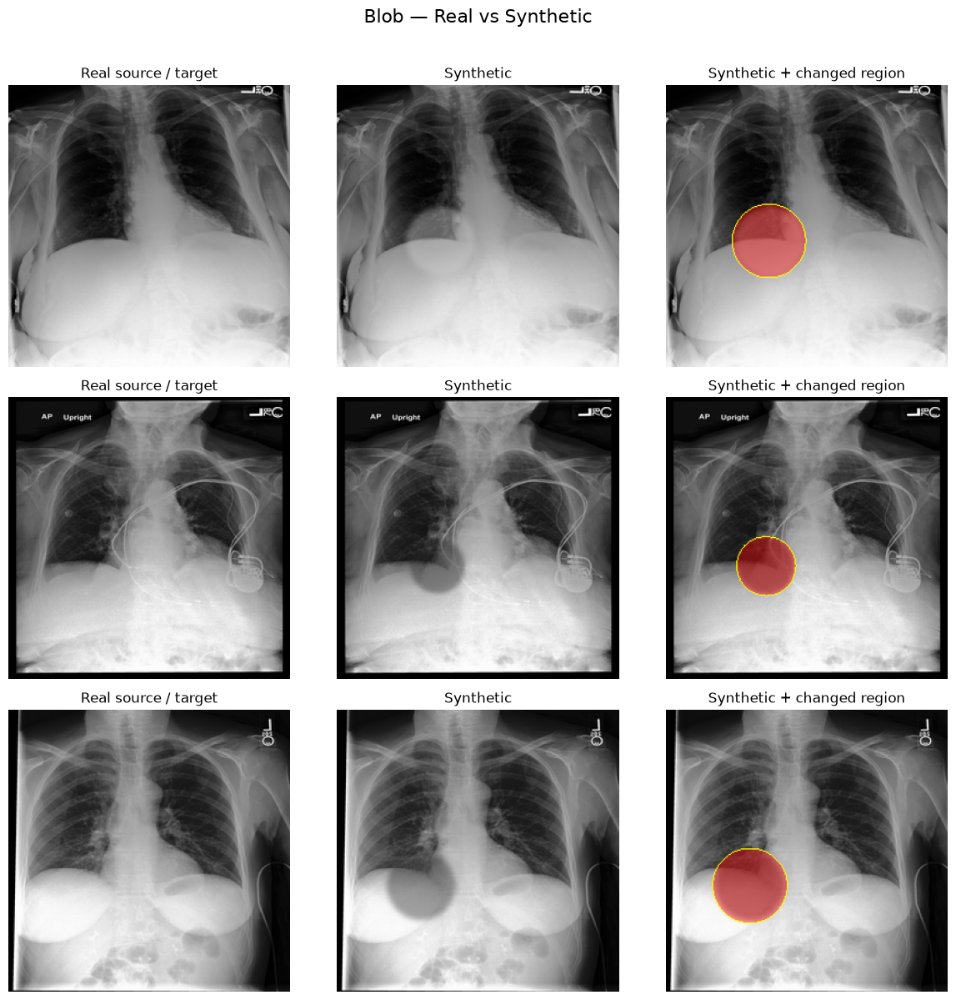


Successfully visualised 3/3 examples.

Metadata: /data/aa8624/thesis_2500/data/synthetic/IP/copy/reports/copy_move_final_metadata.csv
Rows: 2500

Copy-Move
Metadata rows: 2500
Selected examples: 3

Example 1:
  Split:     test
  Disease:   normal
  Real:      /data/aa8624/thesis_2500/data/real/test/normal/p11720780_s56271117_9293f649-267589ed-21194541-6f9ab291-64448feb.jpg
  Synthetic: /data/aa8624/thesis_2500/data/synthetic/IP/copy/test/p11720780_s56271117_9293f649-267589ed-21194541-6f9ab291-64448feb.png
  Mask:      /data/aa8624/thesis_2500/data/synthetic/IP/copy/masks/test/p11720780_s56271117_9293f649-267589ed-21194541-6f9ab291-64448feb_mask.png
  Changed pixels: 2401

Example 2:
  Split:     test
  Disease:   pathology
  Real:      /data/aa8624/thesis_2500/data/real/test/pathology/p15711610_s51269423_d7f7d3a3-93858d0d-d6ffedf0-f9b27cb1-483b6edb.jpg
  Synthetic: /data/aa8624/thesis_2500/data/synthetic/IP/copy/test/p15711610_s51269423_d7f7d3a3-93858d0d-d6ffedf0-f9b27cb1-483b6edb.png

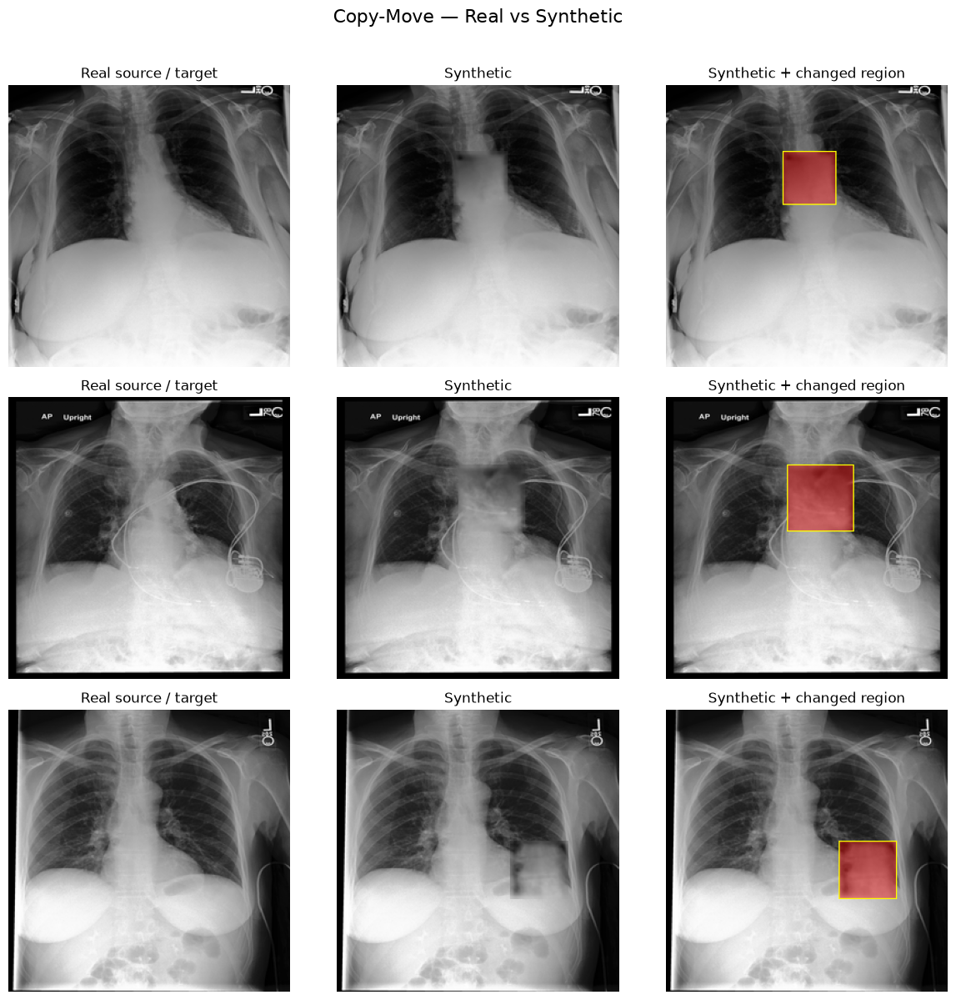


Successfully visualised 3/3 examples.

Metadata: /data/aa8624/thesis_2500/data/synthetic/IP/texture/reports/texture_transplant_final_metadata.csv
Rows: 2500

Texture Transplant
Metadata rows: 2500
Selected examples: 3

Example 1:
  Split:     test
  Disease:   normal
  Real:      /data/aa8624/thesis_2500/data/real/test/normal/p11720780_s56271117_9293f649-267589ed-21194541-6f9ab291-64448feb.jpg
  Synthetic: /data/aa8624/thesis_2500/data/synthetic/IP/texture/test/p11720780_s56271117_9293f649-267589ed-21194541-6f9ab291-64448feb.png
  Mask:      /data/aa8624/thesis_2500/data/synthetic/IP/texture/masks/test/p11720780_s56271117_9293f649-267589ed-21194541-6f9ab291-64448feb_mask.png
  Changed pixels: 3249

Example 2:
  Split:     test
  Disease:   pathology
  Real:      /data/aa8624/thesis_2500/data/real/test/pathology/p15711610_s51269423_d7f7d3a3-93858d0d-d6ffedf0-f9b27cb1-483b6edb.jpg
  Synthetic: /data/aa8624/thesis_2500/data/synthetic/IP/texture/test/p15711610_s51269423_d7f7d3a3-93858d0d-

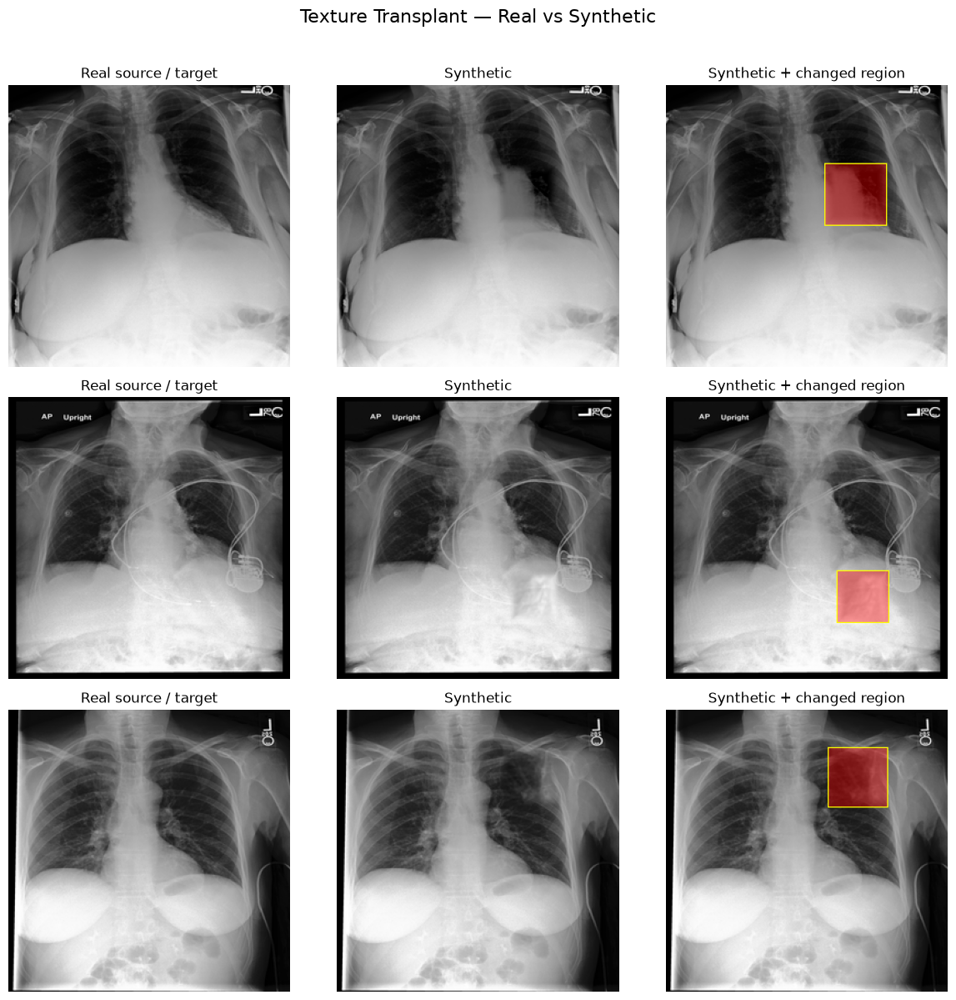


Successfully visualised 3/3 examples.


{'Blob': <Figure size 1200x1200 with 9 Axes>,
 'Copy-Move': <Figure size 1200x1200 with 9 Axes>,
 'Texture Transplant': <Figure size 1200x1200 with 9 Axes>}

In [16]:
# Visual QA of the three IP families
import sys, importlib
sys.path.insert(0, "stage1_generation")          
import visualise_ip_synthetic_qa as vqa
importlib.reload(vqa)

# None = any split
vqa.SPLIT_FILTER = "test"     
# examples per family
vqa.N_EXAMPLES   = 3
# real | synthetic | synthetic + changed region
vqa.visualise_all()           

In [17]:
# edit-strength summary per family for IP
root = config.IP_SYNTHETIC_ROOT
paths = {
    "blob":    root/"blob"/"metadata"/"blob_synthetic_metadata.csv",
    "copy":    root/"copy"/"reports"/"copy_move_final_metadata.csv",
    "texture": root/"texture"/"reports"/"texture_transplant_final_metadata.csv",
}
cols = ["edit_area_fraction", "mean_abs_diff_in_mask", "mean_abs_diff_image"]
for name, p in paths.items():
    d = pd.read_csv(p)
    print(name, len(d), "images")
    print(d[cols].describe().loc[["mean", "min", "max"]].round(3), "\n")

blob 2500 images
      edit_area_fraction  mean_abs_diff_in_mask  mean_abs_diff_image
mean               0.044                 49.344                2.197
min                0.030                 24.921                0.824
max                0.060                 85.324                5.147 

copy 2500 images
      edit_area_fraction  mean_abs_diff_in_mask  mean_abs_diff_image
mean               0.043                 32.194                1.410
min                0.031                  3.300                0.111
max                0.059                130.908                5.536 

texture 2500 images
      edit_area_fraction  mean_abs_diff_in_mask  mean_abs_diff_image
mean               0.045                 22.191                1.004
min                0.031                  1.847                0.060
max                0.061                 75.934                4.453 



In [18]:
# # edit areas via masks
# root = Path("/data/aa8624/thesis/data/synthetic/IP")
# for fam in ["blob", "copy", "texture"]:
#     areas = [ (np.array(Image.open(p).convert("L")) > 127).mean() * 100
#               for p in (root/fam).rglob("*.png") if "mask" in str(p).lower() ]
#     a = np.array(areas)
#     print(fam, len(a), "median %.2f  p5 %.2f  p95 %.2f  min %.2f  max %.2f" %
#           (np.median(a), *np.percentile(a, [5, 95]), a.min(), a.max()))

blob 500 median 4.45  p5 3.15  p95 5.83  min 3.03  max 6.00
copy 500 median 4.29  p5 3.09  p95 5.68  min 3.09  max 5.87
texture 500 median 4.45  p5 3.23  p95 5.87  min 3.09  max 6.06


### Stage 1 (B) — GAN (CycleGAN)

In [19]:
# -----------------------------------------------------------------------------
# CYCLEGAN TRAINING   
# -----------------------------------------------------------------------------
# Trains from scratch on the TRAIN split with Lanczos-resized inputs.
%run stage1_generation/cyclegan_train.py

CYCLEGAN TRAINING FROM SCRATCH
Implementation: direct_pytorch_from_working_html
Pretrained weights: NO
Device: cuda:0
Epochs: 150

CycleGAN dataset validation
  Manifest: /data/aa8624/thesis_2500/data/manifests/real_all.csv
  Training images: 1500
  Domain A: normal (750)
  Domain B: pathology (750)

Normal training images: 750
Pathology training images: 750

Configuration snapshot: /data/aa8624/thesis_2500/data/calibration_cyclegan/configs/cyclegan_lanczos_256_150ep_config.json
Training iterations per epoch: 750

STARTING MODULAR CYCLEGAN TRAINING
Epoch 001/150 | G: 3.3384 | D_A: 0.3201 | D_B: 0.3134 | Cycle: 0.1798 | Identity: 0.1604 | Epoch time: 181.1 s | Elapsed: 0:03:01 | Est. remaining: 7:29:47
Epoch 002/150 | G: 2.4250 | D_A: 0.2548 | D_B: 0.2565 | Cycle: 0.1171 | Identity: 0.1042 | Epoch time: 182.4 s | Elapsed: 0:06:04 | Est. remaining: 7:28:22
Epoch 003/150 | G: 2.1541 | D_A: 0.2483 | D_B: 0.2499 | Cycle: 0.0939 | Identity: 0.0863 | Epoch time: 183.2 s | Elapsed: 0:09:07 | E

Epoch 046/150 | G: 1.4499 | D_A: 0.2194 | D_B: 0.2178 | Cycle: 0.0449 | Identity: 0.0453 | Epoch time: 177.8 s | Elapsed: 2:22:01 | Est. remaining: 5:20:36
Epoch 047/150 | G: 1.4587 | D_A: 0.2219 | D_B: 0.2209 | Cycle: 0.0454 | Identity: 0.0461 | Epoch time: 181.0 s | Elapsed: 2:25:02 | Est. remaining: 5:17:23
Epoch 048/150 | G: 1.4516 | D_A: 0.2194 | D_B: 0.2175 | Cycle: 0.0450 | Identity: 0.0453 | Epoch time: 180.5 s | Elapsed: 2:28:03 | Est. remaining: 5:14:09
Epoch 049/150 | G: 1.4802 | D_A: 0.2180 | D_B: 0.2122 | Cycle: 0.0453 | Identity: 0.0446 | Epoch time: 183.1 s | Elapsed: 2:31:07 | Est. remaining: 5:11:00
Epoch 050/150 | G: 1.4652 | D_A: 0.2171 | D_B: 0.2178 | Cycle: 0.0456 | Identity: 0.0466 | Epoch time: 180.3 s | Elapsed: 2:34:07 | Est. remaining: 5:07:47
Checkpoint: /data/aa8624/thesis_2500/data/calibration_cyclegan/checkpoints/cyclegan_lanczos_256_150ep/epoch_50.pth
Epoch 051/150 | G: 1.4586 | D_A: 0.2182 | D_B: 0.2155 | Cycle: 0.0454 | Identity: 0.0442 | Epoch time: 18


KeyboardInterrupt



<Figure size 640x480 with 0 Axes>

“CycleGAN was trained until epoch 50. The reconstruction losses had plateaued from about epoch 20, and 50 epochs on the 1500-image training set gives more weight updates than the 150-epoch, 500-pool model. A visual check of generated images at epochs 30 and 50 found no artifacts.”

In [31]:
# -----------------------------------------------------------------------------
# CYCLEGAN GENERATION
# -----------------------------------------------------------------------------
# Loads config.CYCLEGAN_FINAL_CHECKPOINT and writes PNGs to
#   data/synthetic/cyclegan/normal_to_pathology/
#   data/synthetic/cyclegan/pathology_to_normal/
%run stage1_generation/cyclegan_generate.py

CYCLEGAN PRODUCTION GENERATION
Manifest validation passed.
  Total images: 2500
  Splits: {'test': 500, 'train': 1500, 'val': 500}
  Disease: {'pathology': 1250, 'normal': 1250}
Loaded CycleGAN checkpoint epoch 50
G_AB: Normal -> Pathology
G_BA: Pathology -> Normal

CYCLEGAN GENERATION COMPLETE
Generated images: 2500
Errors: 0
Metadata: /data/aa8624/thesis_2500/data/synthetic/cyclegan/reports/cyclegan_epoch50_production_metadata.csv
Errors: /data/aa8624/thesis_2500/data/synthetic/cyclegan/reports/cyclegan_epoch50_production_errors.csv


Metadata: /data/aa8624/thesis/data/synthetic/cyclegan/reports/cyclegan_epoch150_production_metadata.csv
Examples per direction: 3
Percentile: 90
Split filter: test
Random seed: 42



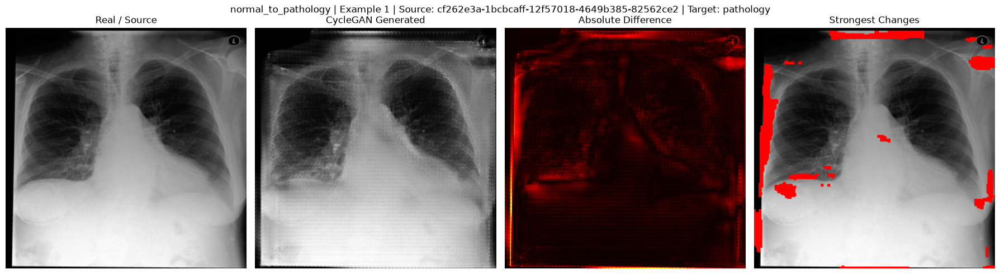

Mean absolute difference: 0.044866
90th percentile threshold: 0.098039
Highlighted area: 6.1508%


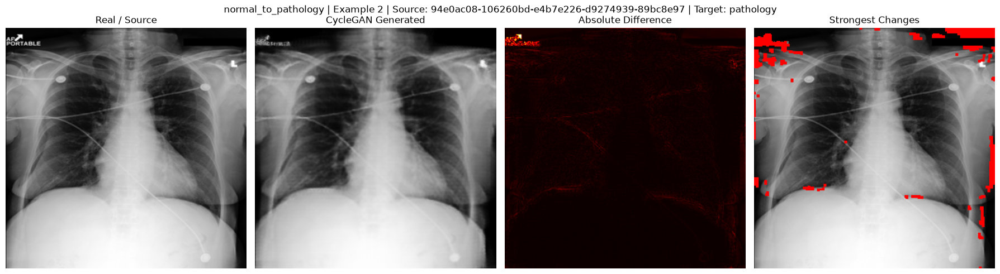

Mean absolute difference: 0.012575
90th percentile threshold: 0.027451
Highlighted area: 3.6423%


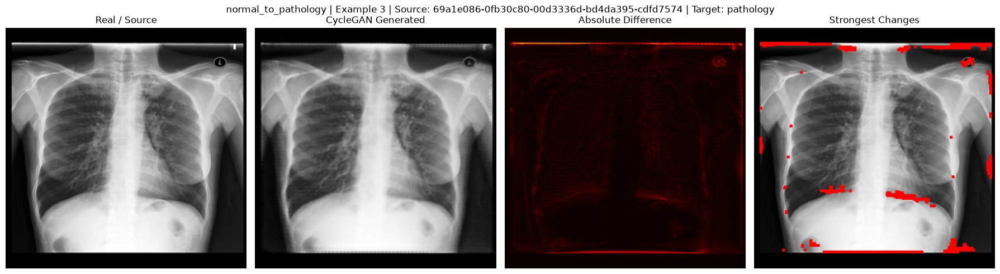

Mean absolute difference: 0.020143
90th percentile threshold: 0.039216
Highlighted area: 3.7155%


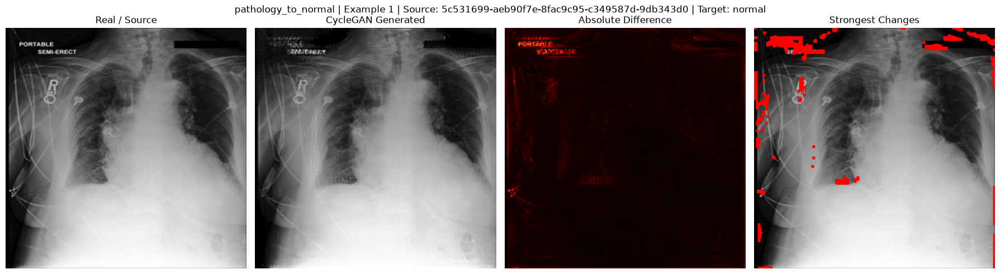

Mean absolute difference: 0.015900
90th percentile threshold: 0.035294
Highlighted area: 3.7491%


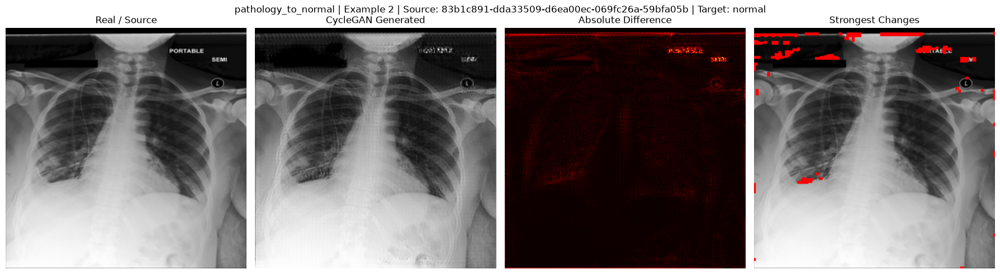

Mean absolute difference: 0.018540
90th percentile threshold: 0.039216
Highlighted area: 2.2324%


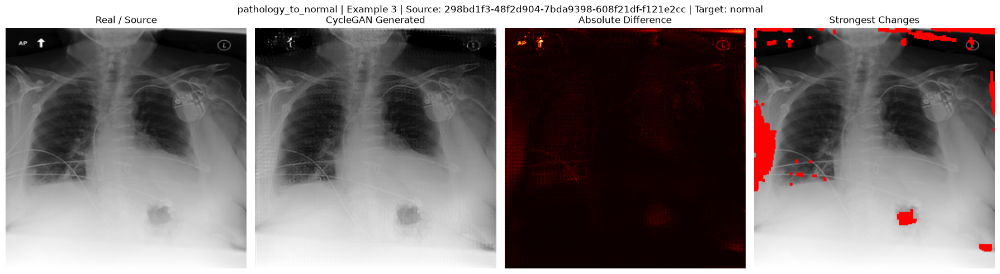

Mean absolute difference: 0.016150
90th percentile threshold: 0.035294
Highlighted area: 5.0522%


In [19]:
# CycleGAN visual QA
import sys, importlib
sys.path.insert(0, "stage1_generation")          
import visualise_cyclegan_qa as cqa
importlib.reload(cqa)                            
cqa.visualise_all(
    n_per_direction=3,        
    split_filter="test",      
)

In [32]:
# CycleGAN change summary per direction

import pandas as pd, config
m = pd.read_csv(config.CYCLEGAN_GENERATION_METADATA)
print(len(m), "images;", m["direction"].value_counts().to_dict())
print(m.groupby("direction")["mean_abs_diff_image"].describe().round(2))

2500 images; {'normal_to_pathology': 1250, 'pathology_to_normal': 1250}
                      count   mean    std   min   25%   50%    75%    max
direction                                                                
normal_to_pathology  1250.0  12.44  12.30  1.53  3.20  6.00  19.40  51.36
pathology_to_normal  1250.0   6.46   6.21  1.44  2.34  3.59   8.57  40.61


### Stage 1 (C) — Diffusion

In [33]:
# Fetch the NIAID repository and checkpoint
import subprocess, hashlib, urllib.request
from pathlib import Path
import config

# --- 1. paths come from config.py -------------
repo = Path(config.DIFFUSION_NIAID_REPO)          # local folder for the NIAID code
ckpt = Path(config.DIFFUSION_NIAID_CHECKPOINT)    # the model weights file inside it

# --- 2. Get the NIAID code -------------------------
repo.parent.mkdir(parents=True, exist_ok=True)    
if repo.exists():
    print("Already cloned:", repo)
else:
    # git clone copies the code, but large files arrive only as LFS pointers
    subprocess.run(["git", "clone", config.DIFFUSION_NIAID_REPO_URL, str(repo)], check=True)

# --- 3. Known facts about the REAL model file (taken from the LFS pointer) -
EXPECTED_SIZE = 73452199                          # bytes
EXPECTED_SHA256 = "57ce04cfd5cd5638115844a83b05205874ce96e9c14d846ab3195015405c51e6"

def is_real_checkpoint(path):
    """True only if the file has the right size AND the right SHA-256 fingerprint."""
    if not path.exists() or path.stat().st_size != EXPECTED_SIZE:
        return False
    return hashlib.sha256(path.read_bytes()).hexdigest() == EXPECTED_SHA256

# --- 4. If we only have the 133-byte placeholder, download the real file ---
if is_real_checkpoint(ckpt):
    print("Checkpoint already correct.")
else:
    url = ("https://media.githubusercontent.com/media/niaid/lung_cxr_segmentation/main/"
           "segment_lung_cxr/data/weights/cxr_lung_segment_including_heart_512.pt")
    urllib.request.urlretrieve(url, ckpt)         # overwrite the placeholder with the real model

# --- 5. Verify: size and fingerprint must both match -----------------------
print("size:", ckpt.stat().st_size, "(expected", EXPECTED_SIZE, ")")
print("sha256 ok:", is_real_checkpoint(ckpt))

Cloning into '/data/aa8624/thesis_2500/data/calibration_diffusion/lung_cxr_segmentation'...


size: 73452199 (expected 73452199 )
sha256 ok: True


In [34]:
# Lung masks for the 500 source images
%run stage1_generation/diffusion_lung_masks.py

I0000 00:00:1792680304.181113 3345790 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792680307.667522 3345790 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792680309.256842 3345790 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


25/2500 processed | success=25 | errors=0
50/2500 processed | success=50 | errors=0
75/2500 processed | success=75 | errors=0
100/2500 processed | success=100 | errors=0
125/2500 processed | success=125 | errors=0
150/2500 processed | success=150 | errors=0
175/2500 processed | success=175 | errors=0
200/2500 processed | success=200 | errors=0
225/2500 processed | success=225 | errors=0
250/2500 processed | success=250 | errors=0
275/2500 processed | success=275 | errors=0
300/2500 processed | success=300 | errors=0
325/2500 processed | success=325 | errors=0
350/2500 processed | success=350 | errors=0
375/2500 processed | success=375 | errors=0
400/2500 processed | success=400 | errors=0
425/2500 processed | success=425 | errors=0
450/2500 processed | success=450 | errors=0
475/2500 processed | success=475 | errors=0
500/2500 processed | success=500 | errors=0
525/2500 processed | success=525 | errors=0
550/2500 processed | success=550 | errors=0
575/2500 processed | success=575 | err

In [35]:
# Check the lung-mask metadata
import config, pandas as pd
m = pd.read_csv(config.DIFFUSION_LUNG_MASK_METADATA)
print(len(m)); print(m.head())

2500
                                       dicom_id  subject_id  study_id  split disease_status view_position                                     lung_mask_path  lung_area_512
0  7d4458a6-5bac467c-5cd22d96-3b6ff9cd-6c482dd0    14493990  50457381  train      pathology            AP  /data/aa8624/thesis_2500/data/calibration_diff...          63726
1  e840352b-bbbe407a-ef5bd148-26204d56-22d59030    11372027  55804244  train      pathology            AP  /data/aa8624/thesis_2500/data/calibration_diff...          52760
2  2ebd3a61-ad335cef-9e8c425b-d15b6644-31ce24c8    19847863  57811099  train         normal            PA  /data/aa8624/thesis_2500/data/calibration_diff...          88940
3  bb632a8f-441f64b0-96db3d52-cbfeb2e7-e61eea56    17629726  53360586  train         normal            PA  /data/aa8624/thesis_2500/data/calibration_diff...          93010
4  36c5341c-9bbe9d41-5e1b067a-05c35b0a-79811e30    13177514  52237063  train      pathology            PA  /data/aa8624/thesis_2500/dat

In [36]:
# Edit masks inside the lungs (production setting: region fraction 0.15)
%run stage1_generation/diffusion_edit_masks.py

Edit-mask mode: area-targeted (target 5.00% of the 512x512 canvas)
25/2500 processed | success=25 | errors=0
50/2500 processed | success=50 | errors=0
75/2500 processed | success=75 | errors=0
100/2500 processed | success=100 | errors=0
125/2500 processed | success=125 | errors=0
150/2500 processed | success=150 | errors=0
175/2500 processed | success=175 | errors=0
200/2500 processed | success=200 | errors=0
225/2500 processed | success=225 | errors=0
250/2500 processed | success=250 | errors=0
275/2500 processed | success=275 | errors=0
300/2500 processed | success=300 | errors=0
325/2500 processed | success=325 | errors=0
350/2500 processed | success=350 | errors=0
375/2500 processed | success=375 | errors=0
400/2500 processed | success=400 | errors=0
425/2500 processed | success=425 | errors=0
450/2500 processed | success=450 | errors=0
475/2500 processed | success=475 | errors=0
500/2500 processed | success=499 | errors=1
525/2500 processed | success=524 | errors=1
550/2500 proces

In [37]:
# RadEdit generation
# Writes: synthetic/diffusion/*
%run stage1_generation/diffusion_generate.py


MANIFEST VALIDATION
Total images: 2500
Disease counts:
disease_status
normal       1250
pathology    1250

Split counts:
split
test      500
train    1500
val       500

Manifest validation: PASS
LOADING MICROSOFT RADEDIT
Device: cuda:0
Dtype : torch.float16

[1/5] Loading RadEdit U-Net...
      PASS

[2/5] Loading SDXL VAE...
      PASS

[3/5] Loading BioViL-T tokenizer...
      PASS (model_max_length=128)

[4/5] Loading BioViL-T text encoder...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] CXRBertModel LOAD REPORT from: microsoft/BiomedVLP-BioViL-T
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


      PASS

[5/5] Creating DDIM scheduler...
      PASS

Building base diffusion pipeline...
      Base pipeline ready.

Converting to RadEdit editing pipeline...


There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


... (102 outputs left out)

Traceback (most recent call last):
  File "/data/aa8624/thesis_2500/cxr_forensics/stage1_generation/diffusion_generate.py", line 808, in generate
    raise FileNotFoundError(
FileNotFoundError: Missing edit mask: /data/aa8624/thesis_2500/data/calibration_diffusion/production_radedit_masks/edit_masks/b3ce913b-568d4863-c5d4d85b-13f06835-62d1cbfa_edit_mask.png



[2431/2500] Pathology_to_Normal
  DICOM       : dffb0ccd-b255c8af-e81ffbad-8e434b9c-0ebcbbe6
  Split       : test
  Seed        : 243117
  Prompt      : chest X-ray with no focal airspace consolidation
  Weight      : 7.5
  Steps       : 200
  Skip ratio  : 0.3
  SUCCESS (2422/2500) elapsed=1031.0 min

[2432/2500] Pathology_to_Normal
  DICOM       : 7dcfbe4f-271b5765-57147931-0560b54f-ea84bba5
  Split       : test
  Seed        : 243217
  Prompt      : chest X-ray with no focal pulmonary opacity
  Weight      : 7.5
  Steps       : 200
  Skip ratio  : 0.3
  SUCCESS (2423/2500) elapsed=1031.4 min

[2433/2500] Pathology_to_Normal
  DICOM       : 9df0db93-01aa5169-75bf2e39-60349e3d-5e6befd1
  Split       : test
  Seed        : 243317
  Prompt      : chest X-ray with no focal pulmonary infiltrate
  Weight      : 7.5
  Steps       : 200
  Skip ratio  : 0.3
  SUCCESS (2424/2500) elapsed=1031.9 min

[2434/2500] Normal_to_Pathology
  DICOM       : 0e20be62-bb9be4b9-f8b81599-46a72bfd-377caad1
 

  SUCCESS (2449/2500) elapsed=1044.0 min

[2459/2500] Pathology_to_Normal
  DICOM       : f3870826-cc6fe781-258e2e17-69473de7-96641185
  Split       : test
  Seed        : 245917
  Prompt      : chest X-ray with no focal pulmonary opacity
  Weight      : 7.5
  Steps       : 200
  Skip ratio  : 0.3
  SUCCESS (2450/2500) elapsed=1044.5 min

[2460/2500] Pathology_to_Normal
  DICOM       : f03cb352-f68cd0dc-edaebbb8-2a5311e2-ef92d6d1
  Split       : test
  Seed        : 246017
  Prompt      : chest X-ray with no focal pulmonary infiltrate
  Weight      : 7.5
  Steps       : 200
  Skip ratio  : 0.3
  SUCCESS (2451/2500) elapsed=1045.1 min

[2461/2500] Pathology_to_Normal
  DICOM       : e555ab70-94334725-68817aef-a4fb65dc-3b3dde9b
  Split       : test
  Seed        : 246117
  Prompt      : chest X-ray with no focal airspace consolidation
  Weight      : 7.5
  Steps       : 200
  Skip ratio  : 0.3
  SUCCESS (2452/2500) elapsed=1045.5 min

[2462/2500] Normal_to_Pathology
  DICOM       : 33743

  SUCCESS (2477/2500) elapsed=1057.3 min

[2487/2500] Pathology_to_Normal
  DICOM       : fa01d1bb-6f68de7a-62d72949-deaa28a2-c179c71a
  Split       : test
  Seed        : 248717
  Prompt      : chest X-ray with no focal pulmonary infiltrate
  Weight      : 7.5
  Steps       : 200
  Skip ratio  : 0.3
  SUCCESS (2478/2500) elapsed=1057.7 min

[2488/2500] Normal_to_Pathology
  DICOM       : e1becc4e-2d2eb2a1-c3aa3c9f-7fbc5e61-39eaa844
  Split       : test
  Seed        : 248817
  Prompt      : chest X-ray with focal airspace consolidation
  Weight      : 7.5
  Steps       : 200
  Skip ratio  : 0.3
  SUCCESS (2479/2500) elapsed=1058.2 min

[2489/2500] Pathology_to_Normal
  DICOM       : fd9bd192-3e5755d2-24236ef9-3c521bc7-5ee1319e
  Split       : test
  Seed        : 248917
  Prompt      : chest X-ray with no focal pulmonary opacity
  Weight      : 7.5
  Steps       : 200
  Skip ratio  : 0.3
  SUCCESS (2480/2500) elapsed=1058.7 min

[2490/2500] Pathology_to_Normal
  DICOM       : 893a995d

Metadata: /data/aa8624/thesis_2500/data/synthetic/diffusion/reports/radedit_production_metadata.csv
Cases per direction: 3
Split filter: test
Normal_to_Pathology: 3 selected
Saved: /data/aa8624/thesis_2500/data/synthetic/diffusion/reports/radedit_visual_QA/RadEdit_visual_QA_Normal_to_Pathology.png
Pathology_to_Normal: 3 selected
Saved: /data/aa8624/thesis_2500/data/synthetic/diffusion/reports/radedit_visual_QA/RadEdit_visual_QA_Pathology_to_Normal.png

RadEdit visual QA complete.
Normal_to_Pathology


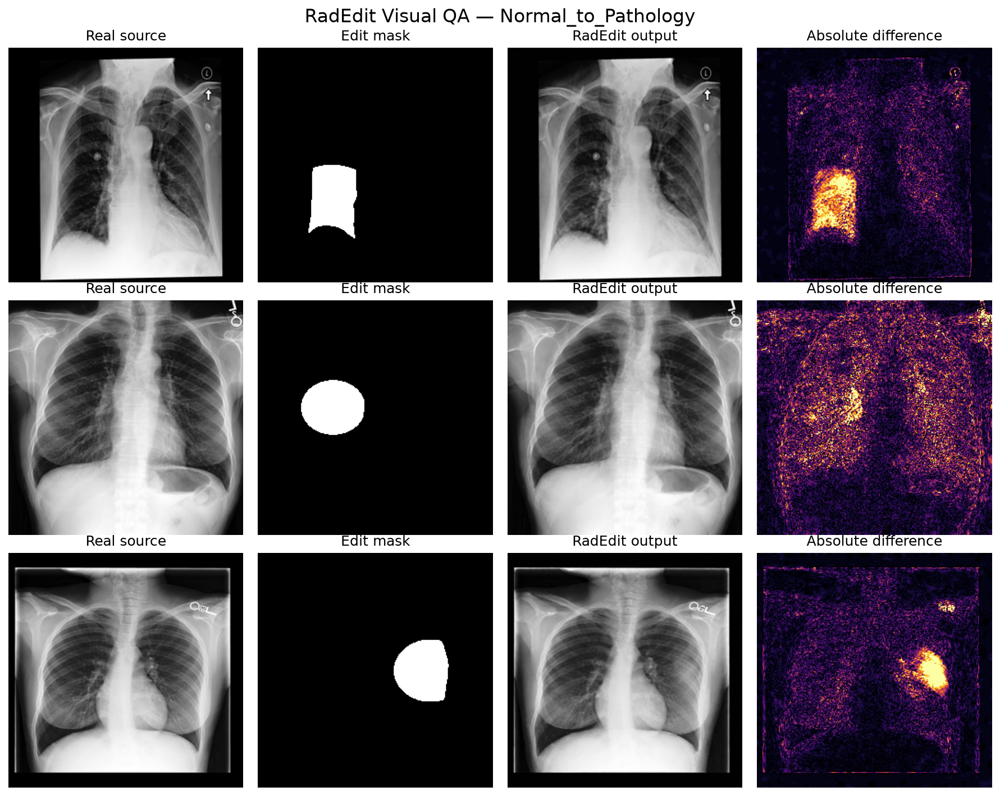

Pathology_to_Normal


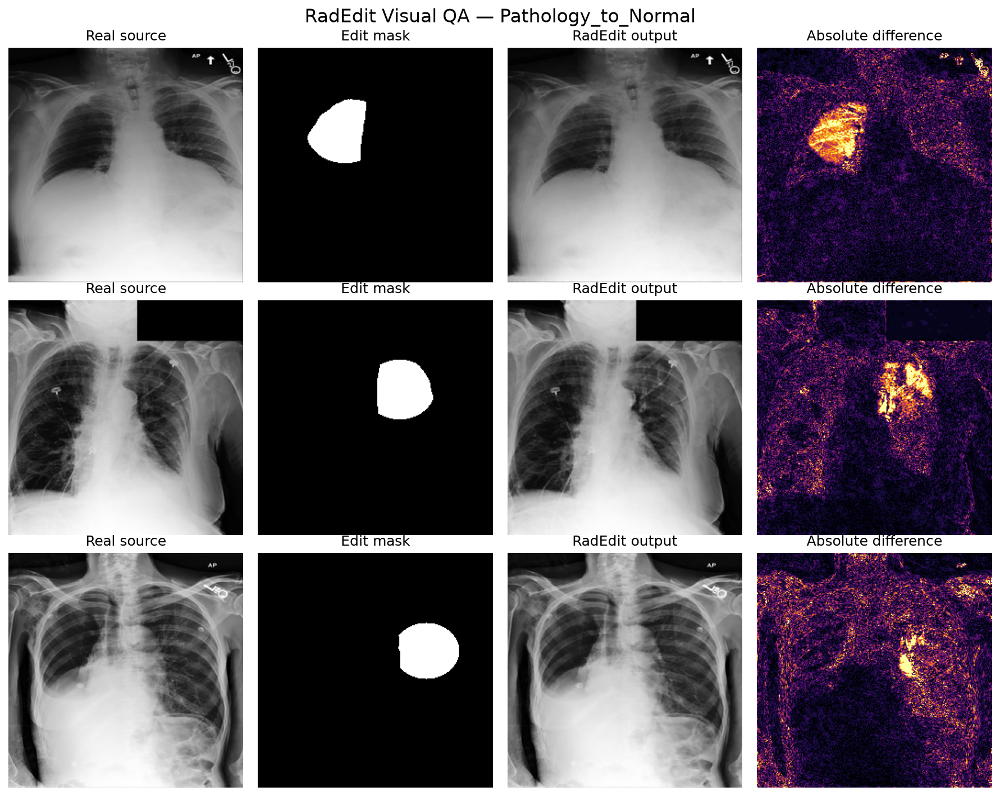

In [38]:
# Visual QA (3 test images per direction)
from IPython.display import display, Image as IPImage
import visualise_diffusion_qa as dvis

dvis.SPLIT_FILTER = "test"
dvis.N_PER_DIRECTION = 3
dvis.visualise_all()

for d in ["Normal_to_Pathology", "Pathology_to_Normal"]:
    p = dvis.OUT_DIR / f"RadEdit_visual_QA_{d}.png"
    print(d)
    display(IPImage(filename=str(p)))

In [39]:
# Statistics of the diffusion edits (how much of the image changed)
meta = pd.read_csv(config.DIFFUSION_PRODUCTION_METADATA)
err = Path(config.DIFFUSION_PRODUCTION_ERRORS)
n_err = len(pd.read_csv(err)) if err.exists() and err.stat().st_size > 0 else 0
print(f"rows {len(meta)} | unique sources {meta['dicom_id'].nunique()} | errors {n_err}")
print(pd.crosstab(meta["split"], meta["direction"]))

print(meta["edit_area_fraction"].describe(percentiles=[.05, .5, .95]).round(4))   # expect ~0.05

for k, v in dict(weight=config.DIFFUSION_WEIGHT, num_inference_steps=config.DIFFUSION_NUM_INFERENCE_STEPS,
                 skip_ratio=config.DIFFUSION_SKIP_RATIO, eta=config.DIFFUSION_ETA,
                 generation_resolution=config.DIFFUSION_GENERATION_SIZE,
                 final_resolution=config.DIFFUSION_FINAL_SIZE).items():
    vals = meta[k].unique()
    print(f"{k:22s} {v}  {vals}  {'OK' if len(vals) == 1 and vals[0] == v else '<-- CHECK'}")

rows 2491 | unique sources 2491 | errors 9
direction  Normal_to_Pathology  Pathology_to_Normal
split                                              
test                       246                  250
train                      747                  748
val                        250                  250
count    2491.00
mean        0.05
std         0.00
min         0.05
5%          0.05
50%         0.05
95%         0.05
max         0.05
Name: edit_area_fraction, dtype: float64
weight                 7.5  [7.5]  OK
num_inference_steps    200  [200]  OK
skip_ratio             0.3  [0.3]  OK
eta                    1.0  [1.]  OK
generation_resolution  512  [512]  OK
final_resolution       256  [256]  OK


In [31]:
# Generation errors
# p = Path(config.DIFFUSION_PRODUCTION_ERRORS)
# e = pd.read_csv(p)
# pd.set_option("display.max_colwidth", 200)
# print(e[["dicom_id", "split", "error"]] if "split" in e else e)

                                       dicom_id  split  \
0  c3d2ebbc-9ead46bb-ac9aefdc-7eb72975-9d7032cb  train   
1  b3ce913b-568d4863-c5d4d85b-13f06835-62d1cbfa  train   
2  2fdacb4c-d1d33652-5ca51506-e3935e00-e024e0aa  train   

                                                                                                                                                                                   error  
0  FileNotFoundError('Missing edit mask: /data/aa8624/thesis/data/calibration_diffusion/production_radedit_masks/edit_masks/c3d2ebbc-9ead46bb-ac9aefdc-7eb72975-9d7032cb_edit_mask.png')  
1  FileNotFoundError('Missing edit mask: /data/aa8624/thesis/data/calibration_diffusion/production_radedit_masks/edit_masks/b3ce913b-568d4863-c5d4d85b-13f06835-62d1cbfa_edit_mask.png')  
2  FileNotFoundError('Missing edit mask: /data/aa8624/thesis/data/calibration_diffusion/production_radedit_masks/edit_masks/2fdacb4c-d1d33652-5ca51506-e3935e00-e024e0aa_edit_mask.png')  


### Stage 1(D) - Diffusion Variants

In [40]:
# Diffusion_EditOnly: paste the RadEdit edit region back into the real source (area-matched soft edge).
%run stage1_generation/diffusion_variants.py edit_only

2491 Diffusion records in the production metadata

written: 2491   missing: 0   folder: /data/aa8624/thesis_2500/data/synthetic/diffusion_editonly
edit area              : 5.00% of the image (mean)
paste blur sigma       : 2.52 px (mean)
mean |change| full     : 2.844 grey levels (RadEdit vs source)
mean |change| edit-only: 0.646 grey levels (edit-only vs source)


<Figure size 640x480 with 0 Axes>

In [41]:
OUT_ROOT = Path(config.SYNTHETIC_DIR) / "diffusion_editonly"
m = pd.read_csv(OUT_ROOT / "diffusion_editonly_metadata.csv")
print(f"written: {len(m)}   folder: {OUT_ROOT}")
print(f"edit area            : {100 * m.edit_area_frac.mean():.2f}% of the image (mean)")
print(f"mean |change| full   : {m.mean_abs_change_full_diffusion.mean():.3f} grey levels")
print(f"mean |change| edit-only: {m.mean_abs_change_edit_only.mean():.3f} grey levels")

written: 2491   folder: /data/aa8624/thesis_2500/data/synthetic/diffusion_editonly
edit area            : 5.00% of the image (mean)
mean |change| full   : 2.844 grey levels
mean |change| edit-only: 0.646 grey levels


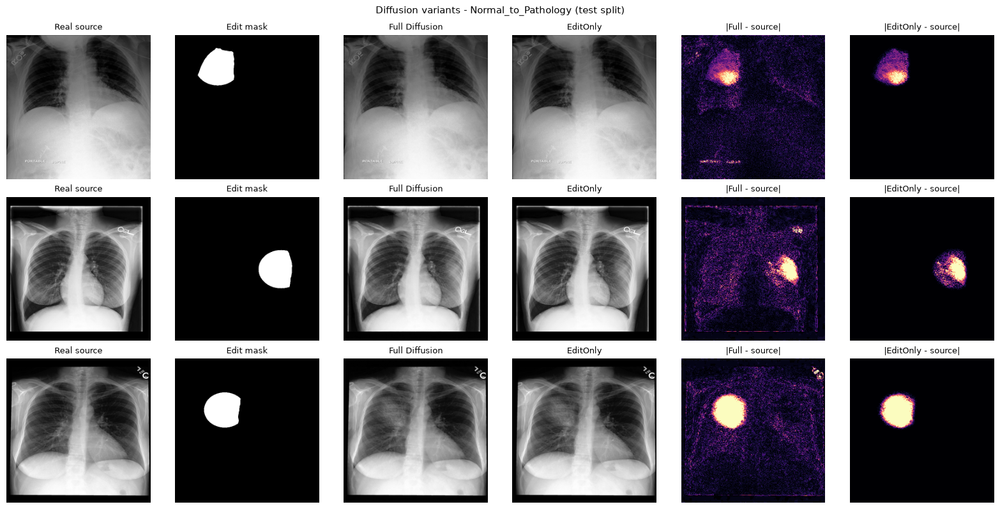

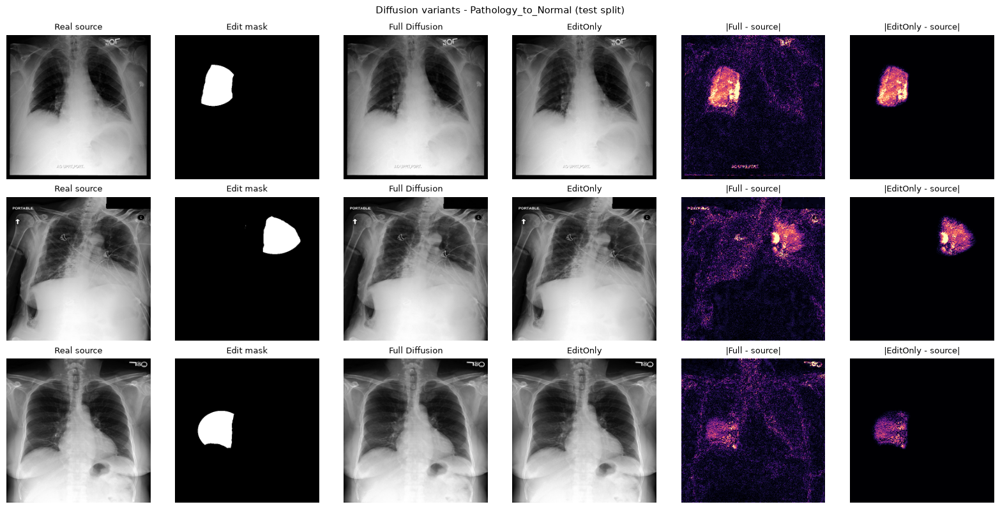

In [42]:
# Visual QA: real source, edit mask, Full vs EditOnly, and their differences from the source.
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
sys.path.insert(0, str(Path("stage1_generation").resolve()))
import diffusion_variants as dv

SPLIT, N_PER_DIRECTION, DIFF_MAX = "test", 3, 25           # DIFF_MAX: one colour scale for both difference panels
grey = lambda im: np.asarray(im.convert("L"), dtype=float)

meta = dv.load_metadata()
eo = pd.read_csv(dv.EDIT_ONLY_ROOT / "diffusion_editonly_metadata.csv", dtype=str).set_index("dicom_id")
meta = meta[(meta.split.str.lower() == SPLIT) & meta.dicom_id.isin(eo.index)]

titles = ["Real source", "Edit mask", "Full Diffusion", "EditOnly", "|Full - source|", "|EditOnly - source|"]
for direction, g in meta.groupby("direction"):
    g = g.head(N_PER_DIRECTION)
    fig, axes = plt.subplots(len(g), 6, figsize=(16, 2.7 * len(g)), squeeze=False)
    for row, r in zip(axes, g.itertuples(index=False)):
        src, full = grey(dv.load_rgb(dv.source_file(r))), grey(dv.load_rgb(r.output_path))
        edit = grey(dv.load_rgb(eo.loc[r.dicom_id, "path"]))
        mask = grey(Image.open(r.edit_mask).resize((dv.FINAL_SIZE,) * 2, Image.Resampling.BOX))
        panels = [(src, "gray", 255), (mask, "gray", 255), (full, "gray", 255), (edit, "gray", 255),
                  (abs(full - src), "magma", DIFF_MAX), (abs(edit - src), "magma", DIFF_MAX)]
        for ax, (img, cmap, vmax), t in zip(row, panels, titles):
            ax.imshow(img, cmap=cmap, vmin=0, vmax=vmax); ax.set_title(t, fontsize=9); ax.axis("off")
    fig.suptitle(f"Diffusion variants - {direction} ({SPLIT} split)", fontsize=11)
    plt.tight_layout(); 
    plt.show()

In [43]:
# Diffusion_Reconstruction: VAE round trip at 512 with no edit (needs the GPU and the SDXL VAE).
%run stage1_generation/diffusion_variants.py reconstruction

device: cuda:0 | dtype: torch.float32
100/2491
200/2491
300/2491
400/2491
500/2491
600/2491
700/2491
800/2491
900/2491
1000/2491
1100/2491
1200/2491
1300/2491
1400/2491
1500/2491
1600/2491
1700/2491
1800/2491
1900/2491
2000/2491
2100/2491
2200/2491
2300/2491
2400/2491

written: 2491   missing: 0   folder: /data/aa8624/thesis_2500/data/synthetic/diffusion_reconstruction
mean |change| recon vs source        : 1.871 grey levels
mean |change| RadEdit vs source      : 2.844
mean |RadEdit - recon| (what the VAE does not explain): 2.086


<Figure size 640x480 with 0 Axes>

In [44]:
# Stats for Diffusion - Reconstruction only
OUT_ROOT = Path(config.SYNTHETIC_DIR) / "diffusion_reconstruction"
m = pd.read_csv(OUT_ROOT / "diffusion_reconstruction_metadata.csv")

print(f"written: {len(m)}   folder: {OUT_ROOT}")
print(f"generator version      : {m.generator_version.unique()}")
print(f"mean |change| recon vs source        : {m.mean_abs_change_recon.mean():.3f} grey levels")
if "mean_abs_change_full_diffusion" in m:
    print(f"mean |change| RadEdit vs source      : {m.mean_abs_change_full_diffusion.mean():.3f}")
    print(f"mean |RadEdit - recon| (what the VAE does NOT explain): {m.mean_abs_diff_diffusion_vs_recon.mean():.3f}")

cols = [c for c in ["mean_abs_change_recon", "mean_abs_change_full_diffusion", "mean_abs_diff_diffusion_vs_recon"] if c in m]
display(m.groupby("direction")[cols].agg(["mean", "std", "min", "max"]).round(2).T)

written: 2491   folder: /data/aa8624/thesis_2500/data/synthetic/diffusion_reconstruction
generator version      : <StringArray>
['stage1_fair_v2']
Length: 1, dtype: str
mean |change| recon vs source        : 1.871 grey levels
mean |change| RadEdit vs source      : 2.844
mean |RadEdit - recon| (what the VAE does NOT explain): 2.086


direction                              Normal_to_Pathology  Pathology_to_Normal
mean_abs_change_recon            mean                 1.86                 1.88
                                 std                  0.46                 0.59
                                 min                  1.18                 1.08
                                 max                  9.54                 9.70
mean_abs_change_full_diffusion   mean                 2.79                 2.90
                                 std                  0.71                 0.78
                                 min                  1.69                 1.70
                                 max                 10.79                11.51
mean_abs_diff_diffusion_vs_recon mean                 2.04                 2.14
                                 std                  0.58                 0.58
                                 min                  1.18                 1.33
                                 max                  6.54                 7.17

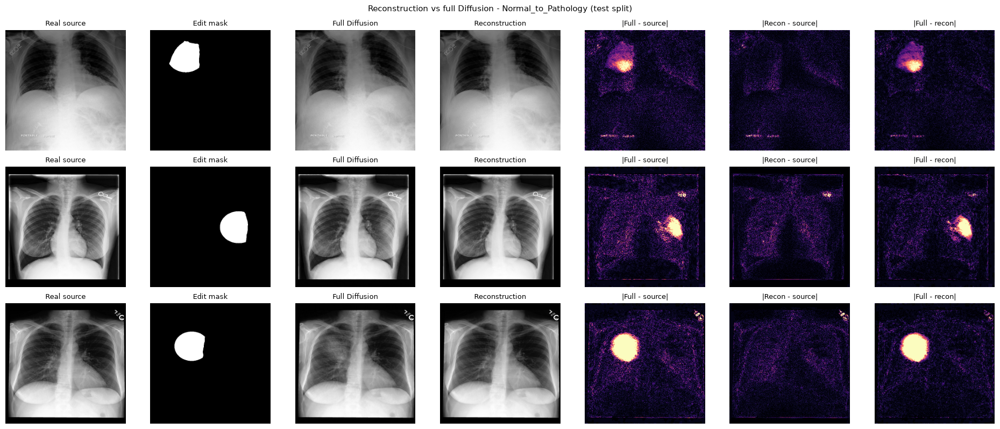

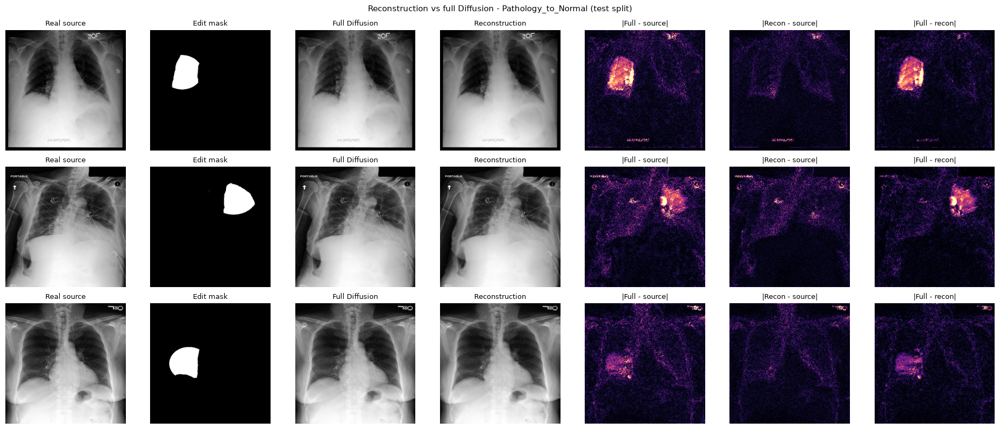

In [7]:
# Visual QA: Reconstruction (VAE only) vs full Diffusion, against the real source.
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
sys.path.insert(0, str(Path("stage1_generation").resolve()))
import diffusion_variants as dv

SPLIT, N_PER_DIRECTION, DIFF_MAX = "test", 3, 25           # DIFF_MAX: one colour scale on all difference panels
grey = lambda im: np.asarray(im.convert("L"), dtype=float)

meta = dv.load_metadata()
rec = pd.read_csv(dv.RECONSTRUCTION_ROOT / "diffusion_reconstruction_metadata.csv", dtype=str).set_index("dicom_id")
meta = meta[(meta.split.str.lower() == SPLIT) & meta.dicom_id.isin(rec.index)]

titles = ["Real source", "Edit mask", "Full Diffusion", "Reconstruction", "|Full - source|", "|Recon - source|", "|Full - recon|"]
for direction, g in meta.groupby("direction"):
    g = g.head(N_PER_DIRECTION)
    fig, axes = plt.subplots(len(g), 7, figsize=(19, 2.7 * len(g)), squeeze=False)
    for row, r in zip(axes, g.itertuples(index=False)):
        src, full = grey(dv.load_rgb(dv.source_file(r))), grey(dv.load_rgb(r.output_path))
        rc = grey(dv.load_rgb(rec.loc[r.dicom_id, "path"]))
        mask = grey(Image.open(r.edit_mask).resize((dv.FINAL_SIZE,) * 2, Image.Resampling.BOX))
        panels = [(src, "gray", 255), (mask, "gray", 255), (full, "gray", 255), (rc, "gray", 255),
                  (abs(full - src), "magma", DIFF_MAX), (abs(rc - src), "magma", DIFF_MAX), (abs(full - rc), "magma", DIFF_MAX)]
        for ax, (img, cmap, vmax), t in zip(row, panels, titles):
            ax.imshow(img, cmap=cmap, vmin=0, vmax=vmax); ax.set_title(t, fontsize=9); ax.axis("off")
    fig.suptitle(f"Reconstruction vs full Diffusion - {direction} ({SPLIT} split)", fontsize=11)
    plt.tight_layout(); 
    plt.show()